


### Verify GPU Runtime


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


### Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


### Extract and Verify the Dataset

In [ ]:
from pathlib import Path
import zipfile

zip_path = Path("/content/drive/MyDrive/syntax.zip")
extract_dir = Path("/content/arcade_data")
extract_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as archive:
    archive.extractall(extract_dir)

train_json_files = list(extract_dir.rglob("train.json"))

if len(train_json_files) != 1:
    raise RuntimeError(
        f"Expected one train.json file, found {len(train_json_files)}"
    )

DATASET_ROOT = train_json_files[0].parents[2]
print("Dataset root:", DATASET_ROOT)

for split in ("train", "val", "test"):
    image_dir = DATASET_ROOT / split / "images"
    mask_dir = DATASET_ROOT / split / "masks"

    image_count = len(list(image_dir.glob("*.png")))
    mask_count = len(list(mask_dir.glob("*.png")))

    print(f"{split}: {image_count} images, {mask_count} masks")

Dataset root: /content/arcade_data/syntax
train: 1000 images, 1000 masks
val: 200 images, 200 masks
test: 300 images, 300 masks


### Define the Dataset and Train the Baseline U-Net

In [ ]:
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset


DATASET_ROOT = Path("/content/arcade_data/syntax")
OUTPUT_DIR = Path("/content/drive/MyDrive/ARCADE_Project/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 512
BATCH_SIZE = 4
NUM_EPOCHS = 5
LEARNING_RATE = 0.001


class ArcadeDataset(Dataset):
    def __init__(self, split):
        self.image_dir = DATASET_ROOT / split / "images"
        self.mask_dir = DATASET_ROOT / split / "masks"
        self.image_files = sorted(self.image_dir.glob("*.png"))

        if not self.image_files:
            raise FileNotFoundError(f"No PNG images found in {self.image_dir}")

        missing_masks = [
            image_file.name
            for image_file in self.image_files
            if not (self.mask_dir / image_file.name).exists()
        ]
        if missing_masks:
            raise FileNotFoundError(
                f"Missing mask for {len(missing_masks)} images. "
                f"First missing file: {missing_masks[0]}"
            )

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, index):
        image_path = self.image_files[index]
        mask_path = self.mask_dir / image_path.name

        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise RuntimeError(f"Could not read image: {image_path}")
        if mask is None:
            raise RuntimeError(f"Could not read mask: {mask_path}")

        if image.shape != (IMAGE_SIZE, IMAGE_SIZE):
            image = cv2.resize(
                image, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA
            )

        if mask.shape != (IMAGE_SIZE, IMAGE_SIZE):
            mask = cv2.resize(
                mask, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_NEAREST
            )

        image = image.astype(np.float32) / 255.0
        mask = (mask > 0).astype(np.float32)

        image_tensor = torch.from_numpy(image).unsqueeze(0)
        mask_tensor = torch.from_numpy(mask).unsqueeze(0)

        return image_tensor, mask_tensor


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.layers(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(1, 8)
        self.enc2 = DoubleConv(8, 16)
        self.enc3 = DoubleConv(16, 32)
        self.enc4 = DoubleConv(32, 64)
        self.bottleneck = DoubleConv(64, 128)

        self.dec4 = DoubleConv(128 + 64, 64)
        self.dec3 = DoubleConv(64 + 32, 32)
        self.dec2 = DoubleConv(32 + 16, 16)
        self.dec1 = DoubleConv(16 + 8, 8)

        self.output_layer = nn.Conv2d(8, 1, kernel_size=1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(self.pool(enc1))
        enc3 = self.enc3(self.pool(enc2))
        enc4 = self.enc4(self.pool(enc3))
        bottleneck = self.bottleneck(self.pool(enc4))

        x = F.interpolate(
            bottleneck, size=enc4.shape[2:], mode="bilinear", align_corners=False
        )
        x = self.dec4(torch.cat([x, enc4], dim=1))

        x = F.interpolate(
            x, size=enc3.shape[2:], mode="bilinear", align_corners=False
        )
        x = self.dec3(torch.cat([x, enc3], dim=1))

        x = F.interpolate(
            x, size=enc2.shape[2:], mode="bilinear", align_corners=False
        )
        x = self.dec2(torch.cat([x, enc2], dim=1))

        x = F.interpolate(
            x, size=enc1.shape[2:], mode="bilinear", align_corners=False
        )
        x = self.dec1(torch.cat([x, enc1], dim=1))

        return self.output_layer(x)


def run_epoch(model, loader, optimizer, device, training):
    model.train(training)

    total_loss = 0.0
    total_intersection = 0.0
    total_predicted = 0.0
    total_target = 0.0

    context = torch.enable_grad() if training else torch.no_grad()

    with context:
        for batch_index, (images, masks) in enumerate(loader, start=1):
            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)
            probabilities = torch.sigmoid(logits)

            bce_loss = F.binary_cross_entropy_with_logits(logits, masks)

            intersection = (probabilities * masks).sum(dim=(1, 2, 3))
            denominator = (
                probabilities.sum(dim=(1, 2, 3))
                + masks.sum(dim=(1, 2, 3))
            )
            dice_loss = 1.0 - (
                (2.0 * intersection + 1.0) / (denominator + 1.0)
            ).mean()

            loss = bce_loss + dice_loss

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()

            predicted_binary = probabilities.detach() >= 0.5
            target_binary = masks >= 0.5

            total_intersection += (predicted_binary & target_binary).sum().item()
            total_predicted += predicted_binary.sum().item()
            total_target += target_binary.sum().item()

            if batch_index % 50 == 0:
                print(f"Processed {batch_index}/{len(loader)} batches")

    mean_loss = total_loss / len(loader)
    dice_score = (2.0 * total_intersection + 1.0) / (
        total_predicted + total_target + 1.0
    )

    return mean_loss, dice_score


def main():
    if not torch.cuda.is_available():
        raise RuntimeError("CUDA GPU is not available. Check the Colab runtime type.")

    device = torch.device("cuda")
    print(f"Using device: {torch.cuda.get_device_name(0)}")

    train_dataset = ArcadeDataset("train")
    val_dataset = ArcadeDataset("val")

    train_loader = DataLoader(
        train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    val_loader = DataLoader(
        val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )

    print(f"Training images: {len(train_dataset)}")
    print(f"Validation images: {len(val_dataset)}")

    model = UNet().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    best_val_dice = -1.0
    checkpoint_path = OUTPUT_DIR / "unet_baseline.pth"

    for epoch in range(1, NUM_EPOCHS + 1):
        print(f"\nEpoch {epoch}/{NUM_EPOCHS}")

        train_loss, train_dice = run_epoch(
            model, train_loader, optimizer, device, training=True
        )
        val_loss, val_dice = run_epoch(
            model, val_loader, optimizer, device, training=False
        )

        print(f"Train loss: {train_loss:.4f}")
        print(f"Train Dice: {train_dice:.4f}")
        print(f"Validation loss: {val_loss:.4f}")
        print(f"Validation Dice: {val_dice:.4f}")

        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save(model.state_dict(), checkpoint_path)
            print(f"Best model saved to: {checkpoint_path}")

    print(f"\nTraining complete. Best validation Dice: {best_val_dice:.4f}")


main()

Using device: Tesla T4
Training images: 1000
Validation images: 200

Epoch 1/5
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 1.0699
Train Dice: 0.5654
Validation loss: 0.8057
Validation Dice: 0.6761
Best model saved to: /content/drive/MyDrive/ARCADE_Project/outputs/unet_baseline.pth

Epoch 2/5
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 0.6325
Train Dice: 0.6949
Validation loss: 0.5362
Validation Dice: 0.6811
Best model saved to: /content/drive/MyDrive/ARCADE_Project/outputs/unet_baseline.pth

Epoch 3/5
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 0.4103
Train Dice: 0.7362
Validation loss: 0.4192
Validation Dice: 0.7121
Best model s

### Evaluate the Baseline U-Net

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_dataset = ArcadeDataset("test")
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

model = UNet().to(device)

checkpoint_path = Path(
    "/content/drive/MyDrive/ARCADE_Project/outputs/unet_baseline.pth"
)
model.load_state_dict(torch.load(checkpoint_path, map_location=device))
model.eval()

true_positive = 0
false_positive = 0
false_negative = 0

with torch.no_grad():
    for batch_index, (images, masks) in enumerate(test_loader, start=1):
        images = images.to(device)
        masks = masks.to(device)

        probabilities = torch.sigmoid(model(images))
        predictions = probabilities >= 0.5
        targets = masks >= 0.5

        true_positive += (predictions & targets).sum().item()
        false_positive += (predictions & ~targets).sum().item()
        false_negative += (~predictions & targets).sum().item()

        if batch_index % 25 == 0:
            print(f"Processed {batch_index}/{len(test_loader)} batches")

dice = (2 * true_positive) / max(
    2 * true_positive + false_positive + false_negative, 1
)
iou = true_positive / max(
    true_positive + false_positive + false_negative, 1
)
precision = true_positive / max(true_positive + false_positive, 1)
recall = true_positive / max(true_positive + false_negative, 1)

print(f"Test Dice: {dice:.4f}")
print(f"Test IoU: {iou:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")

Processed 25/75 batches
Processed 50/75 batches
Processed 75/75 batches
Test Dice: 0.7057
Test IoU: 0.5452
Test Precision: 0.7460
Test Recall: 0.6695


### Visualize Baseline Predictions

Test image: 1.png


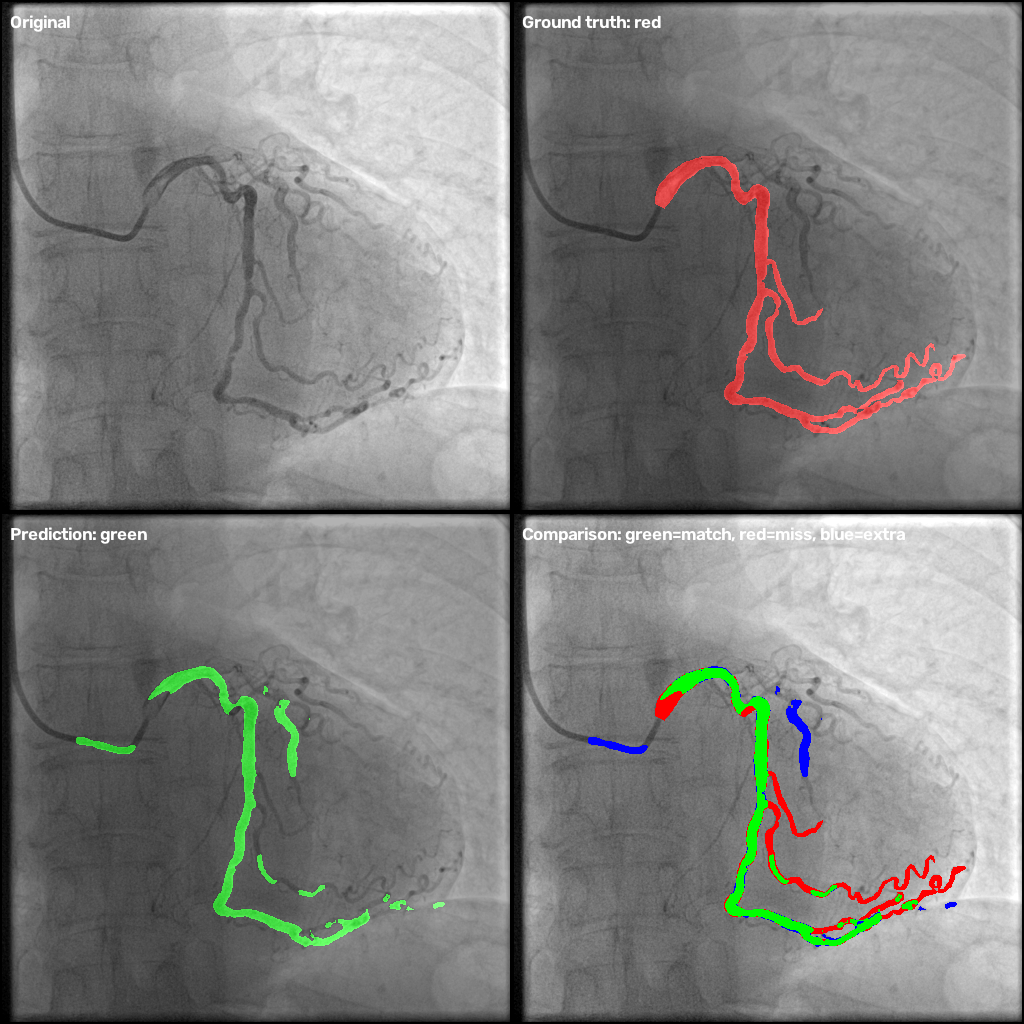

Test image: 10.png


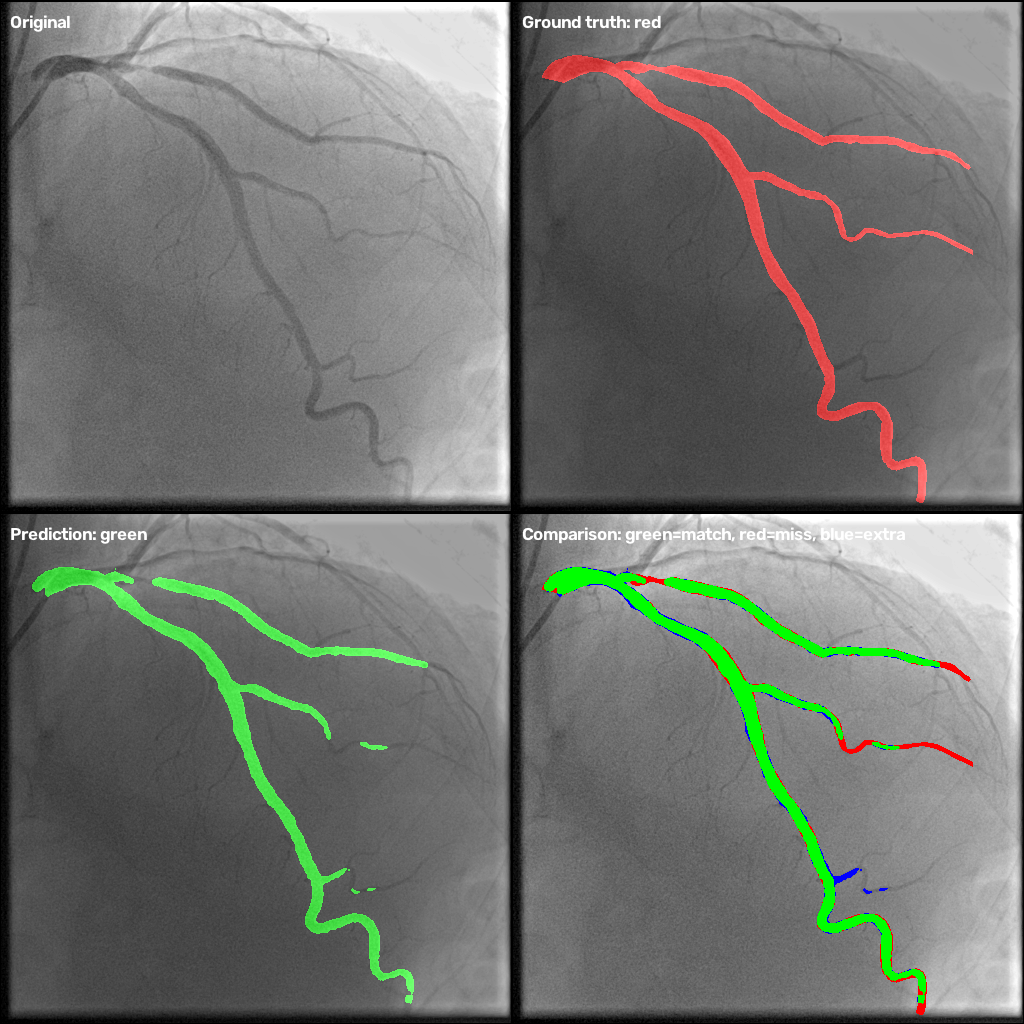

Test image: 100.png


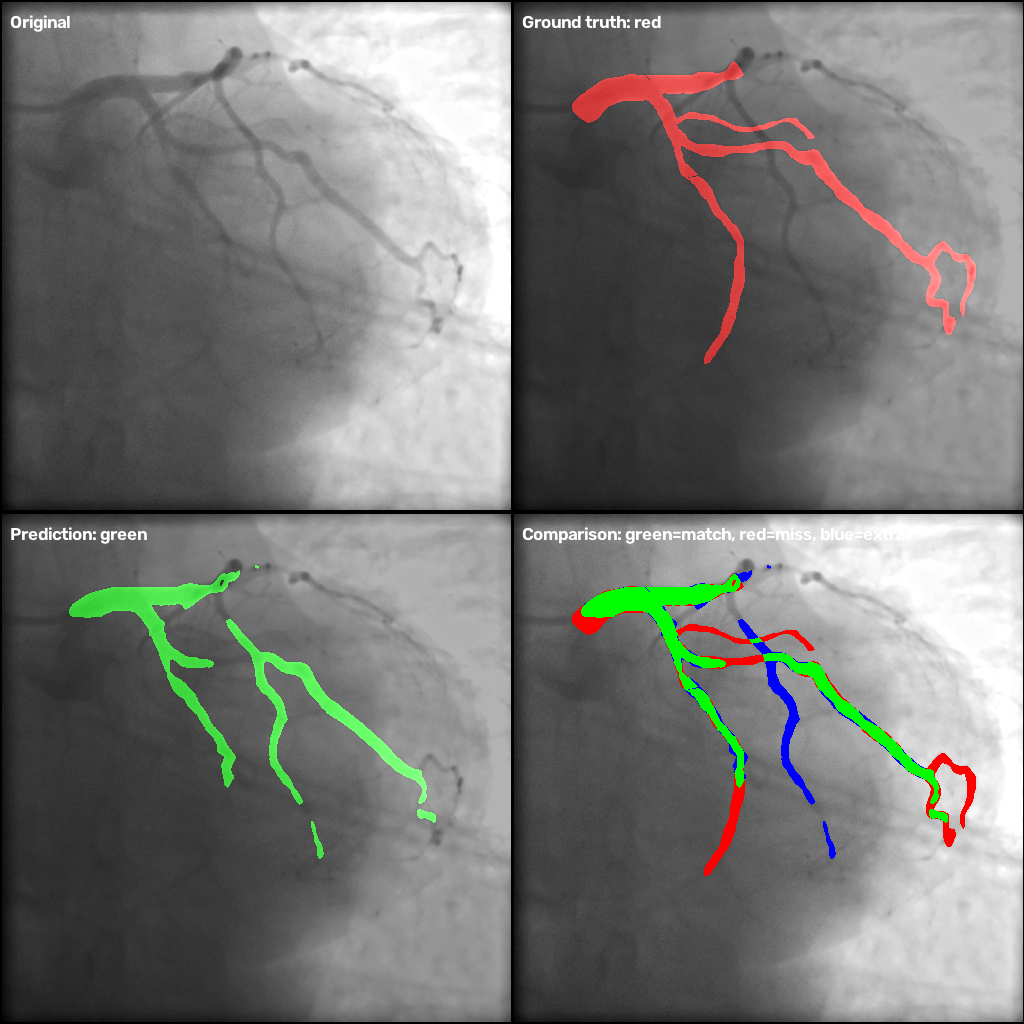

Previews saved in: /content/drive/MyDrive/ARCADE_Project/outputs/test_previews


In [ ]:
from google.colab.patches import cv2_imshow

preview_dir = Path(
    "/content/drive/MyDrive/ARCADE_Project/outputs/test_previews"
)
preview_dir.mkdir(parents=True, exist_ok=True)

for index in range(min(3, len(test_dataset))):
    image_tensor, mask_tensor = test_dataset[index]
    image_name = test_dataset.image_files[index].name

    with torch.no_grad():
        image_batch = image_tensor.unsqueeze(0).to(device)
        probabilities = torch.sigmoid(model(image_batch))[0, 0].cpu().numpy()
        prediction = probabilities >= 0.5

    image = (image_tensor.squeeze().numpy() * 255).astype(np.uint8)
    target = mask_tensor.squeeze().numpy() > 0

    original = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    target_color = np.zeros_like(original)
    target_color[target] = (0, 0, 255)
    target_overlay = cv2.addWeighted(original, 0.7, target_color, 0.6, 0)

    prediction_color = np.zeros_like(original)
    prediction_color[prediction] = (0, 255, 0)
    prediction_overlay = cv2.addWeighted(original, 0.7, prediction_color, 0.6, 0)

    comparison = original.copy()
    comparison[target & prediction] = (0, 255, 0)
    comparison[target & ~prediction] = (0, 0, 255)
    comparison[~target & prediction] = (255, 0, 0)

    tiles = [
        ("Original", original),
        ("Ground truth: red", target_overlay),
        ("Prediction: green", prediction_overlay),
        ("Comparison: green=match, red=miss, blue=extra", comparison),
    ]

    labeled_tiles = []
    for title, tile in tiles:
        tile = tile.copy()
        cv2.putText(
            tile, title, (10, 28),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2
        )
        labeled_tiles.append(tile)

    top_row = np.hstack(labeled_tiles[:2])
    bottom_row = np.hstack(labeled_tiles[2:])
    preview = np.vstack([top_row, bottom_row])

    output_file = preview_dir / f"preview_{index + 1}.png"
    cv2.imwrite(str(output_file), preview)

    print(f"Test image: {image_name}")
    cv2_imshow(preview)

print(f"Previews saved in: {preview_dir}")

### Select a Threshold Using Validation Data

In [ ]:
import numpy as np

val_dataset = ArcadeDataset("val")
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
counts = {threshold: [0, 0, 0] for threshold in thresholds}

model.eval()

with torch.no_grad():
    for batch_index, (images, masks) in enumerate(val_loader, start=1):
        images = images.to(device)
        probabilities = torch.sigmoid(model(images)).cpu().numpy()
        targets = masks.numpy() >= 0.5

        for threshold in thresholds:
            predictions = probabilities >= threshold

            counts[threshold][0] += np.logical_and(predictions, targets).sum()
            counts[threshold][1] += np.logical_and(predictions, ~targets).sum()
            counts[threshold][2] += np.logical_and(~predictions, targets).sum()

        if batch_index % 25 == 0:
            print(f"Processed {batch_index}/{len(val_loader)} batches")

best_threshold = None
best_dice = -1.0

for threshold in thresholds:
    tp, fp, fn = counts[threshold]
    dice = (2 * tp) / max(2 * tp + fp + fn, 1)
    print(f"Threshold {threshold:.1f}: Validation Dice {dice:.4f}")

    if dice > best_dice:
        best_dice = dice
        best_threshold = threshold

print(f"Best threshold: {best_threshold:.1f}")
print(f"Best validation Dice: {best_dice:.4f}")

Processed 25/50 batches
Processed 50/50 batches
Threshold 0.2: Validation Dice 0.7530
Threshold 0.3: Validation Dice 0.7524
Threshold 0.4: Validation Dice 0.7513
Threshold 0.5: Validation Dice 0.7498
Threshold 0.6: Validation Dice 0.7470
Threshold 0.7: Validation Dice 0.7426
Threshold 0.8: Validation Dice 0.7344
Best threshold: 0.2
Best validation Dice: 0.7530


### Define and Train the Attention U-Net

In [ ]:
import random

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader


class AugmentedArcadeDataset(ArcadeDataset):
    def __getitem__(self, index):
        image_tensor, mask_tensor = super().__getitem__(index)

        image = image_tensor.squeeze(0).numpy()
        mask = mask_tensor.squeeze(0).numpy()

        if random.random() < 0.5:
            image = cv2.flip(image, 1)
            mask = cv2.flip(mask, 1)

        if random.random() < 0.5:
            angle = random.uniform(-8.0, 8.0)
            height, width = image.shape
            matrix = cv2.getRotationMatrix2D(
                (width / 2.0, height / 2.0), angle, 1.0
            )

            image = cv2.warpAffine(
                image,
                matrix,
                (width, height),
                flags=cv2.INTER_LINEAR,
                borderMode=cv2.BORDER_CONSTANT,
                borderValue=0,
            )
            mask = cv2.warpAffine(
                mask,
                matrix,
                (width, height),
                flags=cv2.INTER_NEAREST,
                borderMode=cv2.BORDER_CONSTANT,
                borderValue=0,
            )

        if random.random() < 0.5:
            contrast = random.uniform(0.9, 1.1)
            brightness = random.uniform(-0.05, 0.05)
            image = np.clip(image * contrast + brightness, 0.0, 1.0)

        image_tensor = torch.from_numpy(
            np.ascontiguousarray(image, dtype=np.float32)
        ).unsqueeze(0)

        mask_tensor = torch.from_numpy(
            np.ascontiguousarray((mask > 0.5).astype(np.float32))
        ).unsqueeze(0)

        return image_tensor, mask_tensor


class AttentionGate(nn.Module):
    def __init__(self, gate_channels, skip_channels, intermediate_channels):
        super().__init__()

        self.gate_projection = nn.Sequential(
            nn.Conv2d(gate_channels, intermediate_channels, kernel_size=1),
            nn.BatchNorm2d(intermediate_channels),
        )
        self.skip_projection = nn.Sequential(
            nn.Conv2d(skip_channels, intermediate_channels, kernel_size=1),
            nn.BatchNorm2d(intermediate_channels),
        )
        self.attention = nn.Sequential(
            nn.Conv2d(intermediate_channels, 1, kernel_size=1),
            nn.BatchNorm2d(1),
            nn.Sigmoid(),
        )
        self.activation = nn.ReLU(inplace=True)

    def forward(self, gate, skip):
        gate_features = self.gate_projection(gate)
        skip_features = self.skip_projection(skip)
        attention_map = self.attention(
            self.activation(gate_features + skip_features)
        )
        return skip * attention_map


class AttentionUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.pool = nn.MaxPool2d(2)

        self.enc1 = DoubleConv(1, 8)
        self.enc2 = DoubleConv(8, 16)
        self.enc3 = DoubleConv(16, 32)
        self.enc4 = DoubleConv(32, 64)
        self.bottleneck = DoubleConv(64, 128)

        self.gate4 = AttentionGate(128, 64, 32)
        self.gate3 = AttentionGate(64, 32, 16)
        self.gate2 = AttentionGate(32, 16, 8)
        self.gate1 = AttentionGate(16, 8, 4)

        self.dec4 = DoubleConv(128 + 64, 64)
        self.dec3 = DoubleConv(64 + 32, 32)
        self.dec2 = DoubleConv(32 + 16, 16)
        self.dec1 = DoubleConv(16 + 8, 8)

        self.output_layer = nn.Conv2d(8, 1, kernel_size=1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(self.pool(enc1))
        enc3 = self.enc3(self.pool(enc2))
        enc4 = self.enc4(self.pool(enc3))
        bottleneck = self.bottleneck(self.pool(enc4))

        x = F.interpolate(
            bottleneck, size=enc4.shape[2:], mode="bilinear", align_corners=False
        )
        skip = self.gate4(x, enc4)
        x = self.dec4(torch.cat([x, skip], dim=1))

        x = F.interpolate(
            x, size=enc3.shape[2:], mode="bilinear", align_corners=False
        )
        skip = self.gate3(x, enc3)
        x = self.dec3(torch.cat([x, skip], dim=1))

        x = F.interpolate(
            x, size=enc2.shape[2:], mode="bilinear", align_corners=False
        )
        skip = self.gate2(x, enc2)
        x = self.dec2(torch.cat([x, skip], dim=1))

        x = F.interpolate(
            x, size=enc1.shape[2:], mode="bilinear", align_corners=False
        )
        skip = self.gate1(x, enc1)
        x = self.dec1(torch.cat([x, skip], dim=1))

        return self.output_layer(x)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

train_dataset = AugmentedArcadeDataset("train")
val_dataset = ArcadeDataset("val")

train_loader = DataLoader(
    train_dataset, batch_size=4, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_dataset, batch_size=4, shuffle=False, num_workers=0
)

model = AttentionUNet().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

best_val_dice = -1.0
checkpoint_path = OUTPUT_DIR / "attention_unet.pth"

for epoch in range(1, 6):
    print(f"\nEpoch {epoch}/5")

    train_loss, train_dice = run_epoch(
        model, train_loader, optimizer, device, training=True
    )
    val_loss, val_dice = run_epoch(
        model, val_loader, optimizer, device, training=False
    )

    print(f"Train loss: {train_loss:.4f}")
    print(f"Train Dice: {train_dice:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        torch.save(model.state_dict(), checkpoint_path)
        print(f"Best model saved to: {checkpoint_path}")

print(f"\nTraining complete. Best validation Dice: {best_val_dice:.4f}")

Using device: Tesla T4

Epoch 1/5
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 1.3114
Train Dice: 0.3461
Validation loss: 1.0936
Validation Dice: 0.5454
Best model saved to: /content/drive/MyDrive/ARCADE_Project/outputs/attention_unet.pth

Epoch 2/5
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 0.8048
Train Dice: 0.6488
Validation loss: 0.5652
Validation Dice: 0.6942
Best model saved to: /content/drive/MyDrive/ARCADE_Project/outputs/attention_unet.pth

Epoch 3/5
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 0.4988
Train Dice: 0.7005
Validation loss: 0.4589
Validation Dice: 0.6949
Best model saved to: /content/drive/MyDrive/ARCADE_Proj

### Continue Attention U-Net Training

In [ ]:
for param_group in optimizer.param_groups:
    param_group["lr"] = 0.0005

for epoch in range(6, 11):
    print(f"\nEpoch {epoch}/10")

    train_loss, train_dice = run_epoch(
        model, train_loader, optimizer, device, training=True
    )
    val_loss, val_dice = run_epoch(
        model, val_loader, optimizer, device, training=False
    )

    print(f"Train loss: {train_loss:.4f}")
    print(f"Train Dice: {train_dice:.4f}")
    print(f"Validation loss: {val_loss:.4f}")
    print(f"Validation Dice: {val_dice:.4f}")

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        torch.save(model.state_dict(), checkpoint_path)
        print(f"Best model saved to: {checkpoint_path}")

print(f"\nTraining complete. Best validation Dice: {best_val_dice:.4f}")


Epoch 6/10
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 0.3333
Train Dice: 0.7545
Validation loss: 0.3495
Validation Dice: 0.7454
Best model saved to: /content/drive/MyDrive/ARCADE_Project/outputs/attention_unet.pth

Epoch 7/10
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 0.3234
Train Dice: 0.7605
Validation loss: 0.3427
Validation Dice: 0.7522
Best model saved to: /content/drive/MyDrive/ARCADE_Project/outputs/attention_unet.pth

Epoch 8/10
Processed 50/250 batches
Processed 100/250 batches
Processed 150/250 batches
Processed 200/250 batches
Processed 250/250 batches
Processed 50/50 batches
Train loss: 0.3132
Train Dice: 0.7667
Validation loss: 0.3475
Validation Dice: 0.7471

Epoch 9/10
Processed 50/250 batches
Processed 100/250 batches
Processed 15

### Evaluate the Attention U-Net

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

test_dataset = ArcadeDataset("test")
test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

attention_checkpoint = OUTPUT_DIR / "attention_unet.pth"

model = AttentionUNet().to(device)
model.load_state_dict(
    torch.load(attention_checkpoint, map_location=device)
)
model.eval()

true_positive = 0
false_positive = 0
false_negative = 0

with torch.no_grad():
    for batch_index, (images, masks) in enumerate(test_loader, start=1):
        images = images.to(device)
        masks = masks.to(device)

        probabilities = torch.sigmoid(model(images))
        predictions = probabilities >= 0.5
        targets = masks >= 0.5

        true_positive += (predictions & targets).sum().item()
        false_positive += (predictions & ~targets).sum().item()
        false_negative += (~predictions & targets).sum().item()

        if batch_index % 25 == 0:
            print(f"Processed {batch_index}/{len(test_loader)} batches")

dice = (2 * true_positive) / max(
    2 * true_positive + false_positive + false_negative, 1
)
iou = true_positive / max(
    true_positive + false_positive + false_negative, 1
)
precision = true_positive / max(true_positive + false_positive, 1)
recall = true_positive / max(true_positive + false_negative, 1)

print(f"Attention U-Net Test Dice: {dice:.4f}")
print(f"Attention U-Net Test IoU: {iou:.4f}")
print(f"Attention U-Net Test Precision: {precision:.4f}")
print(f"Attention U-Net Test Recall: {recall:.4f}")

Processed 25/75 batches
Processed 50/75 batches
Processed 75/75 batches
Attention U-Net Test Dice: 0.7238
Attention U-Net Test IoU: 0.5672
Attention U-Net Test Precision: 0.7066
Attention U-Net Test Recall: 0.7419


In [ ]:
import numpy as np
from torch.utils.data import DataLoader

val_dataset = ArcadeDataset("val")
val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
counts = {threshold: [0, 0, 0] for threshold in thresholds}

model.eval()

with torch.no_grad():
    for images, masks in val_loader:
        images = images.to(device)
        probabilities = torch.sigmoid(model(images)).cpu().numpy()
        targets = masks.numpy() >= 0.5

        for threshold in thresholds:
            predictions = probabilities >= threshold

            counts[threshold][0] += np.logical_and(predictions, targets).sum()
            counts[threshold][1] += np.logical_and(predictions, ~targets).sum()
            counts[threshold][2] += np.logical_and(~predictions, targets).sum()

best_threshold = None
best_val_dice = -1.0

for threshold in thresholds:
    tp, fp, fn = counts[threshold]
    dice = (2 * tp) / max(2 * tp + fp + fn, 1)

    print(f"Threshold {threshold:.1f}: Validation Dice {dice:.4f}")

    if dice > best_val_dice:
        best_val_dice = dice
        best_threshold = threshold

print(f"\nBest threshold: {best_threshold:.1f}")
print(f"Best validation Dice: {best_val_dice:.4f}")

Threshold 0.2: Validation Dice 0.7630
Threshold 0.3: Validation Dice 0.7658
Threshold 0.4: Validation Dice 0.7675
Threshold 0.5: Validation Dice 0.7686
Threshold 0.6: Validation Dice 0.7695
Threshold 0.7: Validation Dice 0.7700
Threshold 0.8: Validation Dice 0.7698

Best threshold: 0.7
Best validation Dice: 0.7700


### Generate Test-Set Prediction Masks

In [ ]:
prediction_dir = OUTPUT_DIR / "attention_unet_test_masks"
prediction_dir.mkdir(parents=True, exist_ok=True)

model.eval()
batch_size = 4

for start in range(0, len(test_dataset), batch_size):
    indices = list(
        range(start, min(start + batch_size, len(test_dataset)))
    )
    image_tensors = [test_dataset[index][0] for index in indices]
    images = torch.stack(image_tensors).to(device)

    with torch.no_grad():
        probabilities = torch.sigmoid(model(images))
        predictions = (probabilities >= 0.7).cpu().numpy()

    for offset, dataset_index in enumerate(indices):
        image_name = test_dataset.image_files[dataset_index].name
        mask = (predictions[offset, 0] * 255).astype(np.uint8)
        output_file = prediction_dir / image_name

        if not cv2.imwrite(str(output_file), mask):
            raise RuntimeError(f"Could not save mask: {output_file}")

    if (start + batch_size) % 50 == 0:
        print(f"Saved {min(start + batch_size, len(test_dataset))}/"
              f"{len(test_dataset)} masks")

print(f"All test masks saved to: {prediction_dir}")

Saved 100/300 masks
Saved 200/300 masks
Saved 300/300 masks
All test masks saved to: /content/drive/MyDrive/ARCADE_Project/outputs/attention_unet_test_masks


### Evaluate Mask Post-Processing

In [ ]:
val_dataset = ArcadeDataset("val")
val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
THRESHOLD = 0.7

raw_tp = raw_fp = raw_fn = 0
closed_tp = closed_fp = closed_fn = 0

model.eval()

with torch.no_grad():
    for batch_index, (images, masks) in enumerate(val_loader, start=1):
        images = images.to(device)
        probabilities = torch.sigmoid(model(images)).cpu().numpy()
        targets = masks.numpy()[:, 0] >= 0.5

        for index in range(len(targets)):
            raw_prediction = probabilities[index, 0] >= THRESHOLD
            closed_prediction = cv2.morphologyEx(
                raw_prediction.astype(np.uint8),
                cv2.MORPH_CLOSE,
                kernel,
                iterations=1,
            ).astype(bool)

            target = targets[index]

            raw_tp += np.logical_and(raw_prediction, target).sum()
            raw_fp += np.logical_and(raw_prediction, ~target).sum()
            raw_fn += np.logical_and(~raw_prediction, target).sum()

            closed_tp += np.logical_and(closed_prediction, target).sum()
            closed_fp += np.logical_and(closed_prediction, ~target).sum()
            closed_fn += np.logical_and(~closed_prediction, target).sum()

        if batch_index % 25 == 0:
            print(f"Processed {batch_index}/{len(val_loader)} batches")

raw_dice = (2 * raw_tp) / max(2 * raw_tp + raw_fp + raw_fn, 1)
closed_dice = (2 * closed_tp) / max(
    2 * closed_tp + closed_fp + closed_fn, 1
)

print(f"Raw validation Dice: {raw_dice:.4f}")
print(f"Post-processed validation Dice: {closed_dice:.4f}")

Processed 25/50 batches
Processed 50/50 batches
Raw validation Dice: 0.7700
Post-processed validation Dice: 0.7701


### Save Post-Processed Test Masks

In [ ]:
postprocessed_dir = (
    OUTPUT_DIR / "attention_unet_test_masks_postprocessed"
)
postprocessed_dir.mkdir(parents=True, exist_ok=True)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
mask_files = sorted(prediction_dir.glob("*.png"))

for mask_file in mask_files:
    mask = cv2.imread(str(mask_file), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise RuntimeError(f"Could not read mask: {mask_file}")

    processed_mask = cv2.morphologyEx(
        mask, cv2.MORPH_CLOSE, kernel, iterations=1
    )

    output_file = postprocessed_dir / mask_file.name
    if not cv2.imwrite(str(output_file), processed_mask):
        raise RuntimeError(f"Could not save mask: {output_file}")

print(f"Post-processed masks saved: {len(mask_files)}")
print(f"Folder: {postprocessed_dir}")

Post-processed masks saved: 300
Folder: /content/drive/MyDrive/ARCADE_Project/outputs/attention_unet_test_masks_postprocessed


### Visually Compare Ground Truth and Predictions

Test image: 169.png


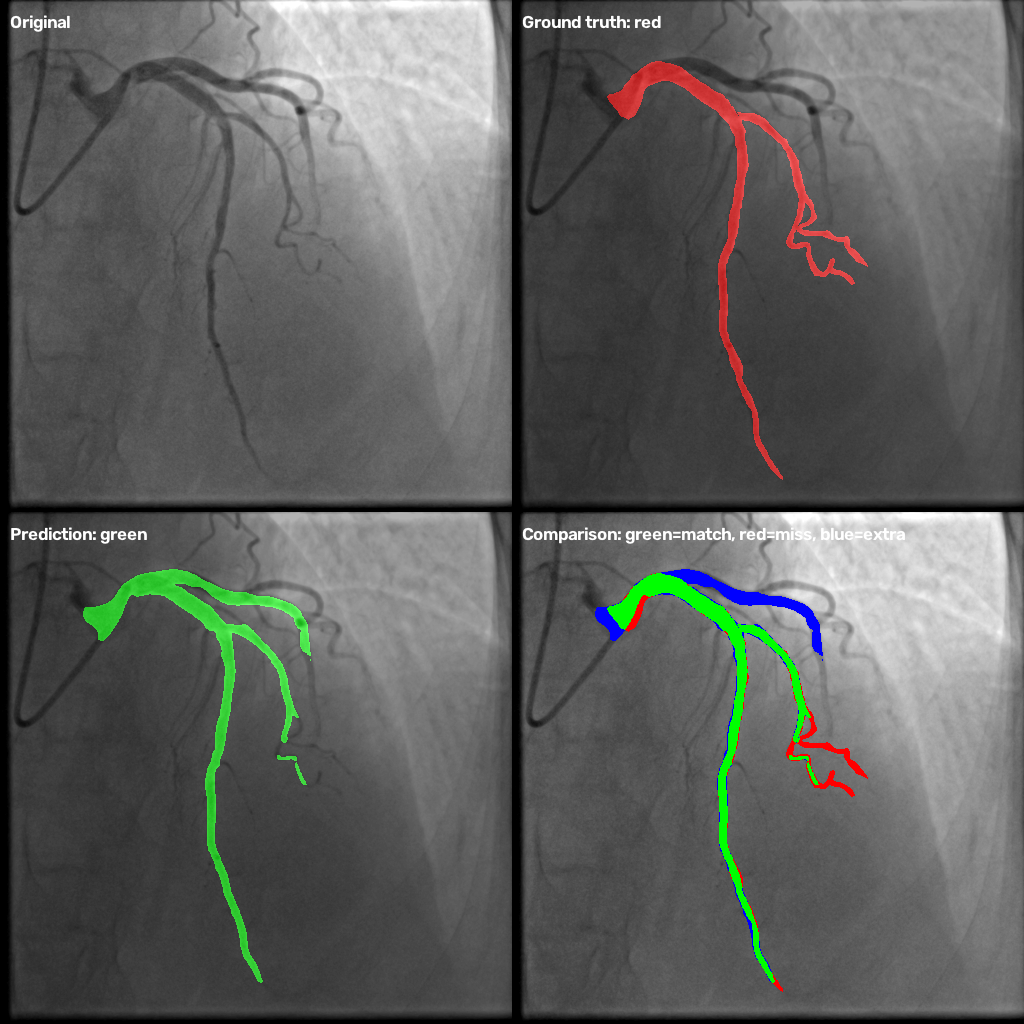

In [ ]:
from google.colab.patches import cv2_imshow

sample_index = 77

image_tensor, ground_truth_tensor = test_dataset[sample_index]
image_name = test_dataset.image_files[sample_index].name

image = (image_tensor.squeeze().numpy() * 255).astype(np.uint8)
ground_truth = ground_truth_tensor.squeeze().numpy() > 0

prediction_path = prediction_dir / image_name
prediction_mask = cv2.imread(
    str(prediction_path), cv2.IMREAD_GRAYSCALE
)

if prediction_mask is None:
    raise RuntimeError(f"Could not read prediction: {prediction_path}")

prediction = prediction_mask > 0
original = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

ground_truth_color = np.zeros_like(original)
ground_truth_color[ground_truth] = (0, 0, 255)
ground_truth_overlay = cv2.addWeighted(
    original, 0.7, ground_truth_color, 0.6, 0
)

prediction_color = np.zeros_like(original)
prediction_color[prediction] = (0, 255, 0)
prediction_overlay = cv2.addWeighted(
    original, 0.7, prediction_color, 0.6, 0
)

comparison = original.copy()
comparison[ground_truth & prediction] = (0, 255, 0)
comparison[ground_truth & ~prediction] = (0, 0, 255)
comparison[~ground_truth & prediction] = (255, 0, 0)

panels = [
    ("Original", original),
    ("Ground truth: red", ground_truth_overlay),
    ("Prediction: green", prediction_overlay),
    ("Comparison: green=match, red=miss, blue=extra", comparison),
]

labeled_panels = []
for title, panel in panels:
    panel = panel.copy()
    cv2.putText(
        panel, title, (10, 28),
        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2
    )
    labeled_panels.append(panel)

top_row = np.hstack(labeled_panels[:2])
bottom_row = np.hstack(labeled_panels[2:])
preview = np.vstack([top_row, bottom_row])

print(f"Test image: {image_name}")
cv2_imshow(preview)

### Skeletonize Masks and Extract Centerlines

Processed 50/300 masks
Processed 100/300 masks
Processed 150/300 masks
Processed 200/300 masks
Processed 250/300 masks
Processed 300/300 masks
Centerlines saved: 300
Folder: /content/drive/MyDrive/ARCADE_Project/outputs/attention_unet_test_centerlines
Centerline overlay: 1.png


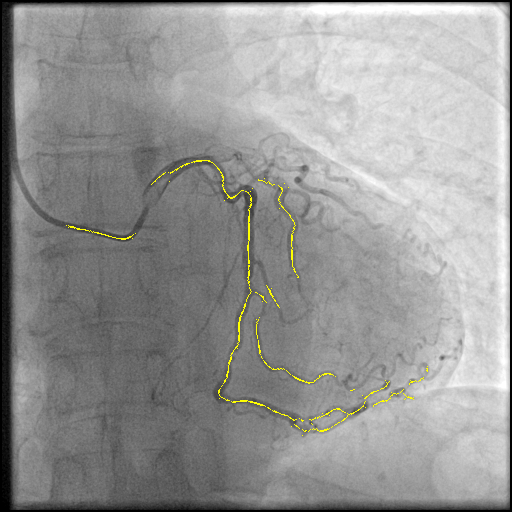

In [ ]:
from google.colab.patches import cv2_imshow

centerline_dir = OUTPUT_DIR / "attention_unet_test_centerlines"
centerline_dir.mkdir(parents=True, exist_ok=True)

skeleton_kernel = cv2.getStructuringElement(
    cv2.MORPH_CROSS, (3, 3)
)
mask_files = sorted(postprocessed_dir.glob("*.png"))

for file_index, mask_file in enumerate(mask_files, start=1):
    mask = cv2.imread(str(mask_file), cv2.IMREAD_GRAYSCALE)

    if mask is None:
        raise RuntimeError(f"Could not read mask: {mask_file}")

    image = (mask > 0).astype(np.uint8) * 255
    skeleton = np.zeros_like(image)

    while cv2.countNonZero(image) > 0:
        eroded = cv2.erode(image, skeleton_kernel)
        opened = cv2.dilate(eroded, skeleton_kernel)
        edge_layer = cv2.subtract(image, opened)
        skeleton = cv2.bitwise_or(skeleton, edge_layer)
        image = eroded

    output_file = centerline_dir / mask_file.name
    if not cv2.imwrite(str(output_file), skeleton):
        raise RuntimeError(f"Could not save centerline: {output_file}")

    if file_index % 50 == 0:
        print(f"Processed {file_index}/{len(mask_files)} masks")

print(f"Centerlines saved: {len(mask_files)}")
print(f"Folder: {centerline_dir}")

sample_index = 0
image_tensor, _ = test_dataset[sample_index]
image_name = test_dataset.image_files[sample_index].name
image = (image_tensor.squeeze().numpy() * 255).astype(np.uint8)
image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

centerline = cv2.imread(
    str(centerline_dir / image_name), cv2.IMREAD_GRAYSCALE
)
overlay = image.copy()
overlay[centerline > 0] = (0, 255, 255)

print(f"Centerline overlay: {image_name}")
cv2_imshow(overlay)

### Save Model Comparison and Performance Reports

In [ ]:
from pathlib import Path
import csv
import json

project_dir = Path("/content/drive/MyDrive/ARCADE_Project")
reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

models = [
    {
        "model": "U-Net baseline",
        "epochs_trained": 5,
        "best_epoch": 4,
        "validation_dice": 0.7498,
        "test_dice": 0.7109,
        "test_iou": 0.5515,
        "test_precision": 0.7117,
        "test_recall": 0.7101,
        "checkpoint": "outputs/unet_baseline.pth",
    },
    {
        "model": "Attention U-Net",
        "epochs_trained": 10,
        "best_epoch": 8,
        "validation_dice": 0.7630,
        "test_dice": 0.7193,
        "test_iou": 0.5617,
        "test_precision": 0.7350,
        "test_recall": 0.7043,
        "checkpoint": "outputs/attention_unet.pth",
    },
]

comparison_csv = reports_dir / "model_comparison.csv"
fieldnames = list(models[0].keys())

with comparison_csv.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(models)

metrics_json = reports_dir / "segmentation_metrics.json"
with metrics_json.open("w", encoding="utf-8") as file:
    json.dump(models, file, indent=2)

report_md = reports_dir / "segmentation_performance_report.md"

report_text = """# ARCADE Artery Segmentation Performance Report

## Dataset and setup

- Dataset: ARCADE XCA syntax track
- Image size: 512 x 512 pixels
- Split: 1000 training, 200 validation, 300 test images
- Target: Binary artery segmentation
- Ground-truth categories 1-25 were combined as artery foreground.
- Category 26 (stenosis) was excluded from artery masks.
- Prediction threshold: 0.5

## Model comparison

| Model | Epochs trained | Best epoch | Validation Dice | Test Dice | Test IoU | Test Precision | Test Recall |
|---|---:|---:|---:|---:|---:|---:|---:|
| U-Net baseline | 5 | 4 | 0.7498 | 0.7109 | 0.5515 | 0.7117 | 0.7101 |
| Attention U-Net | 10 | 8 | 0.7630 | 0.7193 | 0.5617 | 0.7350 | 0.7043 |

## Selected model

Attention U-Net was selected based on its higher validation Dice (0.7630 versus 0.7498).
It also achieved higher test Dice, IoU, and precision than the U-Net baseline.
Its test recall was slightly lower.

## Post-processing

A 3 x 3 morphological closing operation was evaluated on the validation set.
Validation Dice changed from 0.7630 before post-processing to 0.7631 after post-processing.
The difference was negligible.

## Vessel structure outputs

- 300 test prediction masks were generated.
- 300 post-processed masks were generated.
- 300 centerline images were generated.
- Per-image structure metrics and pixel-width estimates were saved as CSV files.

## Limitations

Visual review showed some missed and extra small branches.
The model predicts a binary vessel mask; it does not identify named anatomical branches.
Diameter and length values are pixel-based estimates. Physical calibration was not available,
so they are not reported in millimeters.
The 2D projected mask area is not a true 3D vessel cross-sectional area.
"""

report_md.write_text(report_text, encoding="utf-8")

artifact_paths = [
    comparison_csv,
    report_md,
    metrics_json,
    project_dir / "outputs" / "unet_baseline.pth",
    project_dir / "outputs" / "attention_unet.pth",
    project_dir / "outputs" / "attention_unet_test_structure_report.csv",
]

print("Reports saved:")
for path in artifact_paths:
    print(f"{path} | exists: {path.exists()}")

Reports saved:
/content/drive/MyDrive/ARCADE_Project/reports/model_comparison.csv | exists: True
/content/drive/MyDrive/ARCADE_Project/reports/segmentation_performance_report.md | exists: True
/content/drive/MyDrive/ARCADE_Project/reports/segmentation_metrics.json | exists: True
/content/drive/MyDrive/ARCADE_Project/outputs/unet_baseline.pth | exists: True
/content/drive/MyDrive/ARCADE_Project/outputs/attention_unet.pth | exists: True
/content/drive/MyDrive/ARCADE_Project/outputs/attention_unet_test_structure_report.csv | exists: True
